# Part E: Fair comparison at equal alarm rates

**Why this notebook exists.** In Part D, each predictor used the cut-off set on validation. On the test period those cut-offs gave very different alarm rates (for example about 0.08% of normal hours for the history-free models, 0.48% for model C, and 1.9% for the fixed percentile). A method that raises more alarms finds more events, so those recall numbers are not a fair comparison.

**What this notebook does.** For every predictor it sets the threshold so that the **same share of hours** is flagged, then measures how many labeled events are found. It repeats this over a range of alarm rates, which gives a **recall versus alarm rate** curve for each predictor. The curve does not depend on how any one cut-off was calibrated.

**Two ways to set the threshold**
- **pooled:** one threshold over all buildings, using the error score from Part C.
- **per building:** each building flags its own highest-scoring hours, so every building raises about the same share of alarms and no few buildings dominate.

**No labels are used to set thresholds.** Thresholds come from the score distribution of all valid hours in the evaluated period. Labels are used only afterwards to count found events. This is an analysis of the predictors, not a replacement for the frozen cut-offs of Part C. Report both, and say which is which.

**Alarm rates here are shares of all valid hours.** About 2% of hours in these buildings are labeled anomalies, so at a 0.5% alarm rate the flags cannot cover every labeled hour. Event recall can still be high, because one flagged hour inside an event is enough.

Run the cells in order. Cells marked **CHANGE** may need your file names.

## 0. Settings (CHANGE)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

FLAG_FILE   = "outputs/flags.parquet"                # from Part C (falls back to flags.csv.gz)
EVENT_FILE  = "outputs/lead_events.csv"              # from Part A
INFO_FILE   = "outputs/labeled_buildings_info.csv"   # from Part A
FIXED_FILE  = "outputs/cut_fixed_thresholds.csv"     # from Part C
OUT_DIR     = Path("outputs")

EVAL_SPLIT     = "test"                       # "test" for final numbers, "val" while exploring
RATES_PCT      = [0.1, 0.25, 0.5, 1, 2, 5]    # share of valid hours flagged, in percent
REPORT_RATE    = 1.0                          # the alarm rate used for the length-group table
MODES          = ["pooled", "per_building"]
MAX_ZERO_SHARE = 0.5
RUN_GAP_HOURS  = 1
MIN_EVENTS     = 20
LENGTH_LABELS  = ["1 h", "2-3 h", "4-12 h", ">12 h"]

PRETTY = {"last_hour": "Same as last hour", "typical": "Historical typical value",
          "A": "Model A (no history)", "B": "Model B (+ yesterday, last week)",
          "C": "Model C (+ previous hour)", "fixed": "Fixed percentile"}

## 1. Load flags and events

**What happens:** the score for every valid hour is loaded from the Part C flags file. For the fixed percentile (which has no error score) the score is the reading divided by the building's fixed threshold. Events are filtered exactly as in Part D, so the event counts match.

**What to check:** the event count should match the number in Part D for the same split (587 for test in your run).

In [2]:
def read_any(path):
    p = Path(path)
    stem = p.name.split(".")[0]
    for c in [p, p.with_name(stem + ".csv.gz"), p.with_name(stem + ".csv"), p.with_name(stem + ".parquet")]:
        if c.exists():
            print("reading", c)
            return pd.read_parquet(c) if c.suffix == ".parquet" else pd.read_csv(c)
    raise FileNotFoundError(f"Could not find {path}. Run Part C first.")

flags = read_any(FLAG_FILE)
flags["timestamp"] = pd.to_datetime(flags["timestamp"])
flags = flags[flags["split"] == EVAL_SPLIT].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
flags["t"] = (flags["timestamp"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

info = pd.read_csv(INFO_FILE).set_index("building_id")
flags["is_education"] = flags["building_id"].map(info["primary_use"]).eq("Education")

methods = [c[len("score_"):] for c in flags.columns if c.startswith("score_")]
if "flag_fixed" in flags.columns and Path(FIXED_FILE).exists():
    thr = pd.read_csv(FIXED_FILE, index_col="building_id")["fixed_threshold"]
    flags["score_fixed"] = flags["actual"] / flags["building_id"].map(thr)
    methods.append("fixed")
valid = flags["valid"].to_numpy()
print("methods:", methods, "| valid hours in", EVAL_SPLIT, ":", int(valid.sum()))

ev = pd.read_csv(EVENT_FILE, parse_dates=["start", "end"])
ev["split"] = ev["split"].replace({"validation": "val"})
ev = ev[(ev["split"] == EVAL_SPLIT) & (ev["zero_share"] <= MAX_ZERO_SHARE)
        & ev["building_id"].isin(flags["building_id"].unique())].copy()
ev["s"] = (ev["start"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)
ev["e"] = (ev["end"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

def times_by_building(mask):
    sub = flags[mask]
    return {b: g["t"].to_numpy() for b, g in sub.groupby("building_id")}

def count_in(times, b, lo_t, hi_t):
    t = times.get(b)
    return 0 if t is None else int(np.searchsorted(t, hi_t, "right") - np.searchsorted(t, lo_t, "left"))

vt = times_by_building(flags["valid"])
ev["n_valid"] = [count_in(vt, b, s, e) for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])]
ev = ev[ev["n_valid"] > 0].reset_index(drop=True)
ev["length_group"] = pd.Categorical(ev["length_group"], LENGTH_LABELS, ordered=True)
print("usable events in", EVAL_SPLIT, ":", len(ev))

reading outputs/flags.parquet
methods: ['last_hour', 'typical', 'A', 'B', 'C', 'fixed'] | valid hours in test : 257993
usable events in test : 587


## 2. Set thresholds at equal alarm rates and count found events

**What happens:** for each predictor, each threshold mode and each alarm rate:
1. The threshold is set so that the chosen share of **all valid hours** is flagged (pooled: one global threshold; per building: each building flags its own top share).
2. Flagged hours are grouped into runs.
3. Measured: **event recall** (events with at least one flagged hour), **run precision** (flagged runs touching a labeled hour), **hour precision** (flagged hours that are labeled), and the **actual** share of hours flagged.

Ties can make the actual share slightly different from the target, so the actual share is reported.

In [3]:
def flag_mask(score, mode, rate_pct):
    s = pd.Series(score, index=flags.index).where(flags["valid"])
    if mode == "pooled":
        thr = np.nanquantile(s.to_numpy(), 1 - rate_pct / 100)
        return (s > thr).fillna(False).to_numpy()
    pct = s.groupby(flags["building_id"]).rank(pct=True, method="first")
    return (pct > 1 - rate_pct / 100).fillna(False).to_numpy()

def runs_hit_rate(mask):
    sub = flags[mask]
    if sub.empty:
        return np.nan, 0
    gap = sub.groupby("building_id")["t"].diff()
    rid = (gap.isna() | (gap > RUN_GAP_HOURS)).cumsum()
    hit = sub.groupby(rid)["label"].max()
    return float(hit.mean()), int(len(hit))

def event_found(mask):
    times = times_by_building(pd.Series(mask, index=flags.index))
    return np.array([count_in(times, b, s, e) > 0 for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])])

rows, found_store = [], {}
for mode in MODES:
    for m in methods:
        for r in RATES_PCT:
            mask = flag_mask(flags["score_" + m].to_numpy(), mode, r)
            f = event_found(mask)
            found_store[(mode, m, r)] = f
            run_prec, n_runs = runs_hit_rate(mask)
            edu = ev["is_education"].to_numpy()
            rows.append({"mode": mode, "method": PRETTY.get(m, m), "target_rate_pct": r,
                         "actual_rate_pct": 100 * mask.sum() / valid.sum(),
                         "events": len(ev), "recall_pct": 100 * f.mean(),
                         "recall_education_pct": 100 * f[edu].mean() if edu.any() else np.nan,
                         "runs": n_runs, "run_precision_pct": 100 * run_prec if n_runs else np.nan,
                         "hour_precision_pct": 100 * flags.loc[mask, "label"].mean() if mask.any() else np.nan})
curve = pd.DataFrame(rows)
curve.round(2).to_csv(OUT_DIR / f"eval_equal_rate_{EVAL_SPLIT}.csv", index=False)

pd.set_option("display.width", 220)
for mode in MODES:
    print(f"\nEvent recall (%) at equal alarm rates, threshold mode: {mode}")
    t = curve[curve["mode"] == mode].pivot(index="method", columns="target_rate_pct", values="recall_pct")
    t.columns = [f"{c}% of hours" for c in t.columns]
    print(t.reindex([PRETTY.get(m, m) for m in methods]).round(1).to_string())


Event recall (%) at equal alarm rates, threshold mode: pooled
                                  0.1% of hours  0.25% of hours  0.5% of hours  1.0% of hours  2.0% of hours  5.0% of hours
method                                                                                                                     
Same as last hour                          15.3            21.8           31.3           37.6           42.6           52.3
Historical typical value                    0.9             1.5            2.2            4.8            7.8           16.7
Model A (no history)                        1.0             2.9            4.8            5.6           12.9           22.5
Model B (+ yesterday, last week)            1.4             3.6            6.6           10.2           15.7           27.3
Model C (+ previous hour)                   4.3            12.4           25.0           33.2           45.0           58.9
Fixed percentile                            0.5             0.5      

## 3. Summary: precision at an equal alarm rate, and the area under the curve

**What happens:** two compact comparisons.
- **Run precision at the report rate** (`REPORT_RATE`, 1% of hours by default): of the flagged runs, how many touch a labeled hour.
- **Average recall across the alarm rates:** a single number per predictor, a rough area under the recall curve. It does not depend on any one cut-off.

In [4]:
summ = []
for mode in MODES:
    for m in methods:
        sub = curve[(curve["mode"] == mode) & (curve["method"] == PRETTY.get(m, m))]
        at = sub[np.isclose(sub["target_rate_pct"], REPORT_RATE)].iloc[0]
        summ.append({"mode": mode, "method": PRETTY.get(m, m),
                     f"recall_at_{REPORT_RATE}%": at["recall_pct"],
                     f"run_precision_at_{REPORT_RATE}%": at["run_precision_pct"],
                     f"hour_precision_at_{REPORT_RATE}%": at["hour_precision_pct"],
                     "mean_recall_over_rates": sub["recall_pct"].mean()})
summary = pd.DataFrame(summ)
summary.round(1).to_csv(OUT_DIR / f"eval_equal_rate_summary_{EVAL_SPLIT}.csv", index=False)
print(summary.round(1).to_string(index=False))

        mode                           method  recall_at_1.0%  run_precision_at_1.0%  hour_precision_at_1.0%  mean_recall_over_rates
      pooled                Same as last hour            37.6                   11.0                    11.5                    33.5
      pooled         Historical typical value             4.8                   16.6                    16.7                     5.7
      pooled             Model A (no history)             5.6                    9.6                    21.8                     8.3
      pooled Model B (+ yesterday, last week)            10.2                    9.2                    28.3                    10.8
      pooled        Model C (+ previous hour)            33.2                   17.9                    28.8                    29.8
      pooled                 Fixed percentile             1.7                   14.1                     5.0                     3.3
per_building                Same as last hour            38.7        

## 4. Recall by event length at the report rate

**What happens:** event recall split by length group, at the same alarm rate for every predictor, for both threshold modes. Groups with fewer than `MIN_EVENTS` events are marked.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), c + h)

rows = []
for mode in MODES:
    for scope in ["All labeled buildings", "Education only"]:
        em = np.ones(len(ev), bool) if scope.startswith("All") else ev["is_education"].to_numpy()
        for lg in LENGTH_LABELS:
            gm = em & (ev["length_group"] == lg).to_numpy()
            n = int(gm.sum())
            for m in methods:
                k = int(found_store[(mode, m, REPORT_RATE)][gm].sum())
                lo, hi = wilson(k, n)
                rows.append({"mode": mode, "scope": scope, "length_group": lg, "method": PRETTY.get(m, m),
                             "events": n, "found": k, "recall_pct": round(100 * k / n, 1) if n else np.nan,
                             "low_pct": round(100 * lo, 1), "high_pct": round(100 * hi, 1), "few_events": n < MIN_EVENTS})
bylen = pd.DataFrame(rows)
bylen.to_csv(OUT_DIR / f"eval_equal_rate_by_length_{EVAL_SPLIT}.csv", index=False)
for mode in MODES:
    print(f"\nRecall (%) by event length at {REPORT_RATE}% of hours flagged, all labeled buildings, mode: {mode}")
    sub = bylen[(bylen["mode"] == mode) & (bylen["scope"] == "All labeled buildings")]
    tab = sub.pivot(index="method", columns="length_group", values="recall_pct")[LENGTH_LABELS]
    cnt = sub[sub["method"] == sub["method"].iloc[0]].set_index("length_group")["events"]
    tab.columns = [f"{c} (n={cnt[c]})" for c in LENGTH_LABELS]
    print(tab.reindex([PRETTY.get(m, m) for m in methods]).to_string())


Recall (%) by event length at 1.0% of hours flagged, all labeled buildings, mode: pooled
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
method                                                                                   
Same as last hour                        42.5          55.4            25.9          32.7
Historical typical value                  0.0           3.3             2.7          20.4
Model A (no history)                      0.0           3.3             3.8          23.5
Model B (+ yesterday, last week)          0.5           7.6             9.2          35.7
Model C (+ previous hour)                26.9          46.7            28.1          43.9
Fixed percentile                          0.0           2.2             2.7           3.1

Recall (%) by event length at 1.0% of hours flagged, all labeled buildings, mode: per_building
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
meth

## 5. Figure: recall versus alarm rate

**What happens:** one panel per threshold mode. The higher a line is at a given alarm rate, the more events that predictor finds for the same cost. Saved for the report and slides.

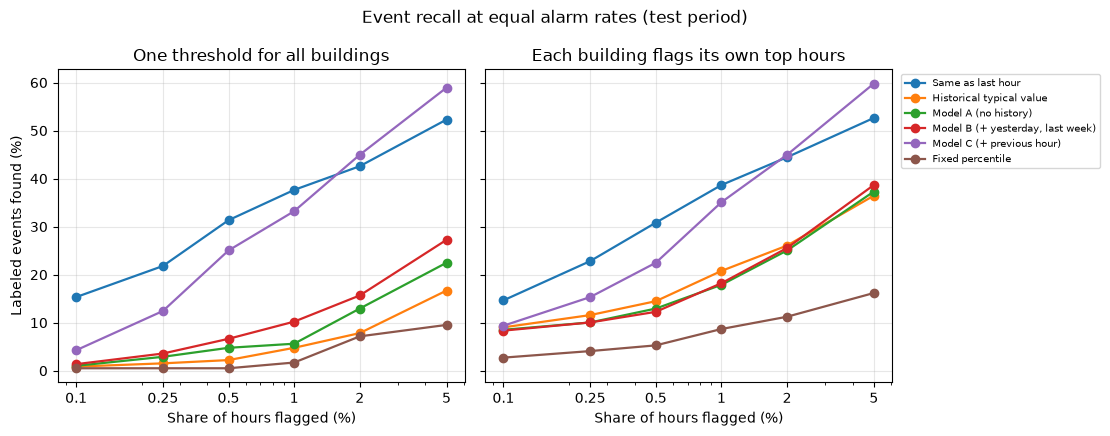

saved: eval_equal_rate_test.csv, eval_equal_rate_summary_test.csv, eval_equal_rate_by_length_test.csv, eval_equal_rate_curve_test.png


In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(MODES), figsize=(5.6 * len(MODES), 4.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, mode in zip(axes, MODES):
    for m in methods:
        sub = curve[(curve["mode"] == mode) & (curve["method"] == PRETTY.get(m, m))]
        ax.plot(sub["target_rate_pct"], sub["recall_pct"], marker="o", lw=1.6, label=PRETTY.get(m, m))
    ax.set_xscale("log")
    ax.set_xticks(RATES_PCT)
    ax.set_xticklabels([str(r) for r in RATES_PCT])
    ax.set_xlabel("Share of hours flagged (%)")
    ax.set_title("One threshold for all buildings" if mode == "pooled" else "Each building flags its own top hours")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Labeled events found (%)")
axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(f"Event recall at equal alarm rates ({EVAL_SPLIT} period)")
plt.tight_layout()
plt.savefig(OUT_DIR / f"eval_equal_rate_curve_{EVAL_SPLIT}.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved: eval_equal_rate_%s.csv, eval_equal_rate_summary_%s.csv, eval_equal_rate_by_length_%s.csv, eval_equal_rate_curve_%s.png" % ((EVAL_SPLIT,) * 4))

## 6. How to read and report this

1. **Compare lines at the same alarm rate.** This is the fair comparison. If a predictor is above another at every rate, it is better at finding labeled events for the same alarm cost.
2. **Report both threshold modes.** If they agree on the order of the predictors, say so; the finding is then robust to how the threshold is set. If they disagree, say that too.
3. **Keep the Part D numbers, and label them.** Part D is the result of the pre-set cut-offs; this notebook is the equal-rate analysis. State plainly that the cut-offs did not carry over equally from validation to test.
4. **The comparison with the simple baseline matters.** If the same-as-last-hour predictor is close to model C, then the previous hour does most of the work, and the model adds little beyond it for this label set.
5. **Short events are the test of whether a method adds value.** Compare the 1 h and 2-3 h columns.
6. **Do not overclaim.** Labels are human judgments from plots, LEAD comes from the same source as GEPIII, and unlabeled hours are treated as normal. Event counts inside one building are not independent.